In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
candidate_roots = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'truck_model_cpp']
PROJECT_ROOT = next(
    (root for root in candidate_roots if (root / 'experements' / 'csv').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Не найден каталог truck_model_cpp/experements/csv')

ZERO_PATH = PROJECT_ROOT / 'experements' / 'csv' / 'trajectory_zero.csv'
MPPI_PATH = PROJECT_ROOT / 'experements' / 'csv' / 'trajectory_mppi.csv'

required = {
    't', 'x', 'y',
    'psi_tractor', 'psi_trailer',
    'vx', 'vy',
    'r1', 'r2',
    'delta'
}


def load_trajectory(csv_path):
    if not csv_path.exists():
        candidates = list(Path.cwd().rglob(csv_path.name))

        if len(candidates) == 1:
            csv_path = candidates[0]
        else:
            raise FileNotFoundError(
                f'Не найден файл {csv_path.name}. '
                'Положите notebook рядом с CSV-файлами.'
            )

    df = pd.read_csv(csv_path)

    missing = required.difference(df.columns)
    if missing:
        raise ValueError(
            f'В файле {csv_path.name} отсутствуют колонки: '
            f'{sorted(missing)}'
        )

    df['articulation'] = (
        df['psi_tractor'] - df['psi_trailer']
    )
    df['sideslip'] = np.arctan2(df['vy'], df['vx'])

    print(f'Файл: {csv_path.resolve()}')
    print(
        f'Строк: {len(df)}, интервал: '
        f'{df.t.iloc[0]:.3f} ... {df.t.iloc[-1]:.3f} с'
    )

    return df


df_zero = load_trajectory(ZERO_PATH)
df_mppi = load_trajectory(MPPI_PATH)

display(df_zero.head())
display(df_mppi.head())

Файл: /Users/leryamerlen/Desktop/Diplomchik/truck_model_cpp/experements/csv/trajectory_zero.csv
Строк: 26, интервал: 0.000 ... 5.000 с
Файл: /Users/leryamerlen/Desktop/Diplomchik/truck_model_cpp/experements/csv/trajectory_mppi.csv
Строк: 26, интервал: 0.000 ... 5.000 с


,t,x,y,psi_tractor,psi_trailer,vx,vy,r1,r2,delta,steering_rate,longitudinal_acceleration,articulation,sideslip
0,0.0,0.000000,0.000000,0.000000,-0.080000,15.000000,1.000000,0.100000,-0.100000,0.0,0.0,0.0,0.080000,0.066568
1,0.2,2.998216,0.157081,0.016063,-0.094261,14.994453,0.392354,0.061255,-0.034445,0.0,0.0,0.0,0.110324,0.026161
2,0.4,5.995466,0.269704,0.025051,-0.091723,14.995216,0.142654,0.030323,0.062744,0.0,0.0,0.0,0.116774,0.009513
3,0.6,8.992515,0.370336,0.028872,-0.068656,14.988502,0.061352,0.010090,0.162319,0.0,0.0,0.0,0.097528,0.004093
4,0.8,11.986675,0.466603,0.030474,-0.036220,14.968812,0.012956,0.007657,0.147277,0.0,0.0,0.0,0.066694,0.000866


,t,x,y,psi_tractor,psi_trailer,vx,vy,r1,r2,delta,steering_rate,longitudinal_acceleration,articulation,sideslip
0,0.0,0.000000,0.000000,0.000000,-0.080000,15.000000,1.000000,0.100000,-0.100000,0.000000,-0.019037,-0.002796,0.080000,0.066568
1,0.2,2.999306,0.155950,0.015547,-0.094269,15.008112,0.380410,0.052765,-0.034722,-0.010634,-0.055809,0.150084,0.109816,0.025342
2,0.4,6.001492,0.259072,0.020835,-0.092000,15.025006,0.125218,0.002019,0.059641,-0.015923,0.020354,0.088755,0.112835,0.008334
3,0.6,9.005738,0.336749,0.017864,-0.070163,15.019676,0.076626,-0.026781,0.153192,-0.010239,0.044319,0.067604,0.088027,0.005102
4,0.8,12.006625,0.396926,0.012565,-0.040067,14.991551,0.070379,-0.022413,0.132787,-0.002423,0.027550,0.094393,0.052632,0.004695


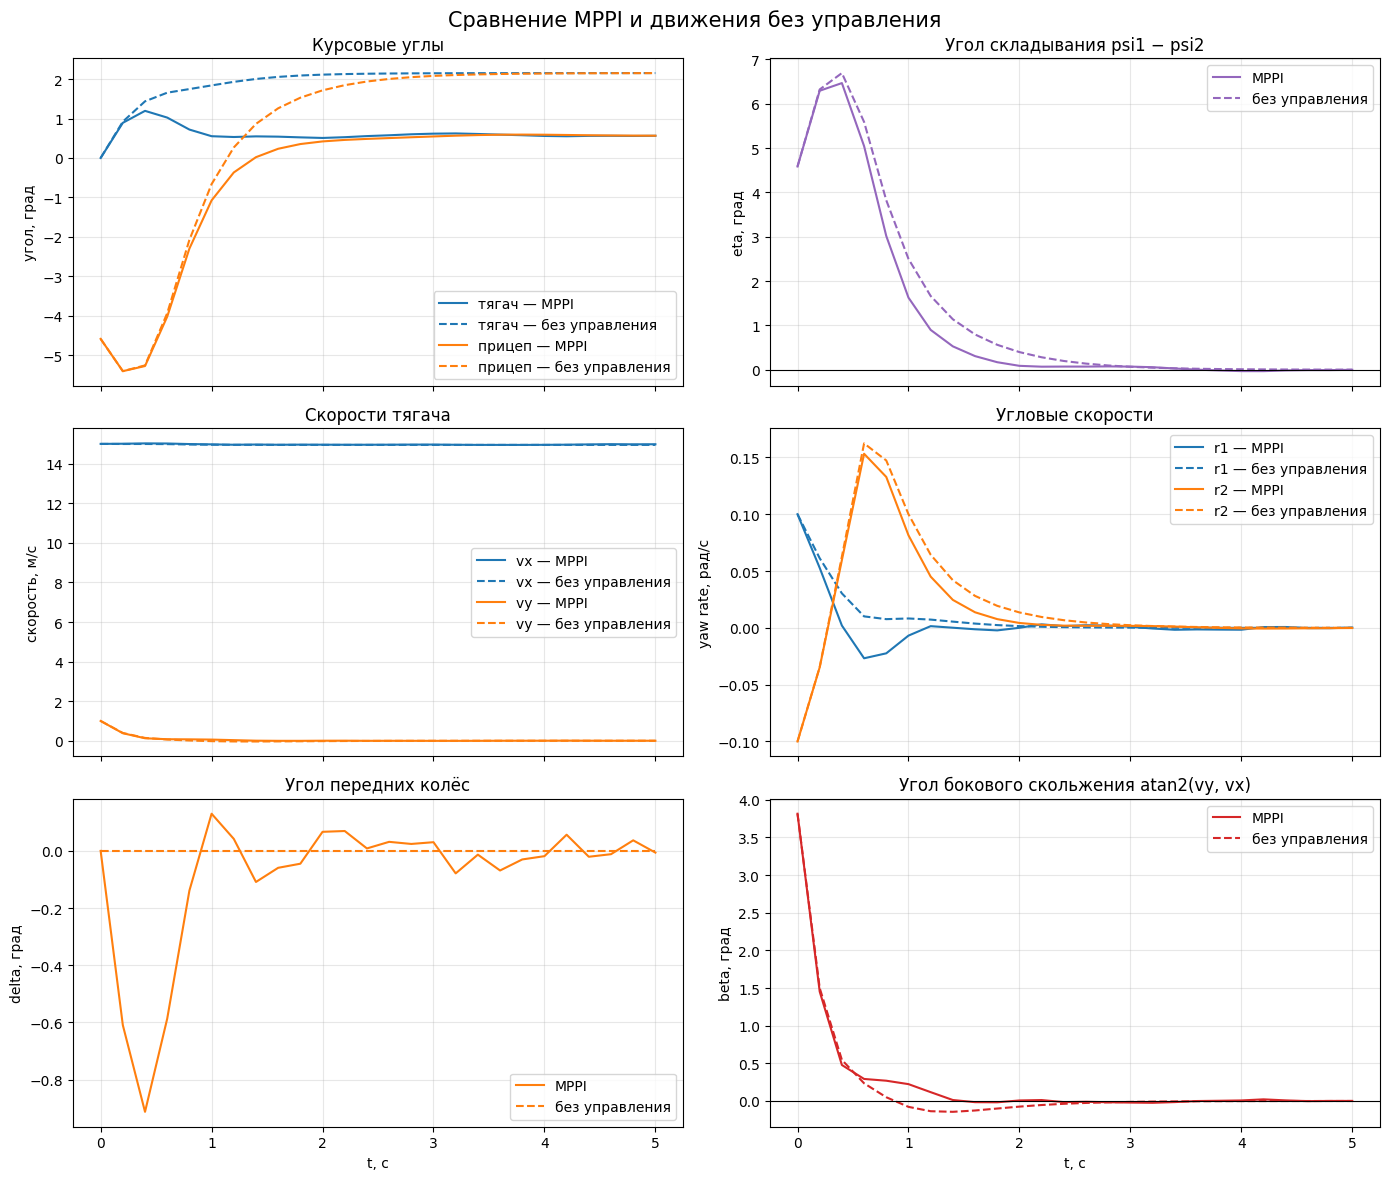

In [3]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 12),
    sharex=True
)

# 1. Курсовые углы
axes[0, 0].plot(
    df_mppi.t,
    np.rad2deg(df_mppi.psi_tractor),
    color='tab:blue',
    linestyle='-',
    label='тягач — MPPI'
)
axes[0, 0].plot(
    df_zero.t,
    np.rad2deg(df_zero.psi_tractor),
    color='tab:blue',
    linestyle='--',
    label='тягач — без управления'
)
axes[0, 0].plot(
    df_mppi.t,
    np.rad2deg(df_mppi.psi_trailer),
    color='tab:orange',
    linestyle='-',
    label='прицеп — MPPI'
)
axes[0, 0].plot(
    df_zero.t,
    np.rad2deg(df_zero.psi_trailer),
    color='tab:orange',
    linestyle='--',
    label='прицеп — без управления'
)
axes[0, 0].set_ylabel('угол, град')
axes[0, 0].set_title('Курсовые углы')
axes[0, 0].legend()

# 2. Угол складывания
axes[0, 1].plot(
    df_mppi.t,
    np.rad2deg(df_mppi.articulation),
    color='tab:purple',
    linestyle='-',
    label='MPPI'
)
axes[0, 1].plot(
    df_zero.t,
    np.rad2deg(df_zero.articulation),
    color='tab:purple',
    linestyle='--',
    label='без управления'
)
axes[0, 1].axhline(
    0,
    color='black',
    linewidth=0.8
)
axes[0, 1].set_ylabel('eta, град')
axes[0, 1].set_title('Угол складывания psi1 − psi2')
axes[0, 1].legend()

# 3. Скорости тягача
axes[1, 0].plot(
    df_mppi.t,
    df_mppi.vx,
    color='tab:blue',
    linestyle='-',
    label='vx — MPPI'
)
axes[1, 0].plot(
    df_zero.t,
    df_zero.vx,
    color='tab:blue',
    linestyle='--',
    label='vx — без управления'
)
axes[1, 0].plot(
    df_mppi.t,
    df_mppi.vy,
    color='tab:orange',
    linestyle='-',
    label='vy — MPPI'
)
axes[1, 0].plot(
    df_zero.t,
    df_zero.vy,
    color='tab:orange',
    linestyle='--',
    label='vy — без управления'
)
axes[1, 0].set_ylabel('скорость, м/с')
axes[1, 0].set_title('Скорости тягача')
axes[1, 0].legend()

# 4. Угловые скорости
axes[1, 1].plot(
    df_mppi.t,
    df_mppi.r1,
    color='tab:blue',
    linestyle='-',
    label='r1 — MPPI'
)
axes[1, 1].plot(
    df_zero.t,
    df_zero.r1,
    color='tab:blue',
    linestyle='--',
    label='r1 — без управления'
)
axes[1, 1].plot(
    df_mppi.t,
    df_mppi.r2,
    color='tab:orange',
    linestyle='-',
    label='r2 — MPPI'
)
axes[1, 1].plot(
    df_zero.t,
    df_zero.r2,
    color='tab:orange',
    linestyle='--',
    label='r2 — без управления'
)
axes[1, 1].set_ylabel('yaw rate, рад/с')
axes[1, 1].set_title('Угловые скорости')
axes[1, 1].legend()

# 5. Угол передних колёс
axes[2, 0].plot(
    df_mppi.t,
    np.rad2deg(df_mppi.delta),
    color='tab:orange',
    linestyle='-',
    label='MPPI'
)
axes[2, 0].plot(
    df_zero.t,
    np.rad2deg(df_zero.delta),
    color='tab:orange',
    linestyle='--',
    label='без управления'
)
axes[2, 0].set_ylabel('delta, град')
axes[2, 0].set_title('Угол передних колёс')
axes[2, 0].set_xlabel('t, с')
axes[2, 0].legend()

# 6. Боковое скольжение
axes[2, 1].plot(
    df_mppi.t,
    np.rad2deg(df_mppi.sideslip),
    color='tab:red',
    linestyle='-',
    label='MPPI'
)
axes[2, 1].plot(
    df_zero.t,
    np.rad2deg(df_zero.sideslip),
    color='tab:red',
    linestyle='--',
    label='без управления'
)
axes[2, 1].axhline(
    0,
    color='black',
    linewidth=0.8
)
axes[2, 1].set_ylabel('beta, град')
axes[2, 1].set_title('Угол бокового скольжения atan2(vy, vx)')
axes[2, 1].set_xlabel('t, с')
axes[2, 1].legend()

# Сетка на всех графиках
for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.suptitle(
    'Сравнение MPPI и движения без управления',
    fontsize=15
)

fig.tight_layout()
plt.show()